In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

In [6]:
# Load dataset
DATA_PATH = Path("../../../data/coconut_health/stage1/data/cococare_stage1_outputs/stage1_hybrid_dataset.csv")
df = pd.read_csv(DATA_PATH)

In [9]:
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)


# Original weather features
weather_features = [
    "rainfall_mm",
    "tmax_c",
    "tmin_c",
    "solar_radiation_mj_m2_day",
    "relative_humidity_pct",
    "wind_speed_m_s"
]

# Additional weather-derived experiment
et0_feature = ["et0_mm_day"]

# Create historical features
for col in weather_features:

    # Previous day's observation
    df[f"{col}_lag1"] = df[col].shift(1)

    # Rolling averages for temperature, humidity, etc.
    if col != "rainfall_mm":
        for window in [3, 7, 14]:
            df[f"{col}_rolling_mean_{window}d"] = (
                df[col].rolling(window).mean()
            )

# Rainfall accumulation
for window in [3, 7, 14]:
    df[f"rainfall_sum_{window}d"] = (
        df["rainfall_mm"].rolling(window).sum()
    )

# Seasonal features
day_of_year = df["date"].dt.dayofyear

df["day_sin"] = np.sin(2 * np.pi * day_of_year / 365.25)
df["day_cos"] = np.cos(2 * np.pi * day_of_year / 365.25)





In [10]:
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)

# Original weather features
weather_features = [
    "rainfall_mm",
    "tmax_c",
    "tmin_c",
    "solar_radiation_mj_m2_day",
    "relative_humidity_pct",
    "wind_speed_m_s"
]

# Additional weather-derived experiment
et0_feature = ["et0_mm_day"]

# Create historical features
for col in weather_features:

    # Previous day's observation
    df[f"{col}_lag1"] = df[col].shift(1)

    # Rolling averages for temperature, humidity, etc.
    if col != "rainfall_mm":
        for window in [3, 7, 14]:
            df[f"{col}_rolling_mean_{window}d"] = (
                df[col].rolling(window).mean()
            )

# Rainfall accumulation
for window in [3, 7, 14]:
    df[f"rainfall_sum_{window}d"] = (
        df["rainfall_mm"].rolling(window).sum()
    )

# Seasonal features
day_of_year = df["date"].dt.dayofyear

df["day_sin"] = np.sin(2 * np.pi * day_of_year / 365.25)
df["day_cos"] = np.cos(2 * np.pi * day_of_year / 365.25)

# Target for current-day classification
df["target_current"] = df["water_stress_rule_derived"]

# Target for next-day prediction
df["target_next_day"] = (
    df["water_stress_rule_derived"].shift(-1)
)

# Actual date associated with each prediction target
df["target_date_current"] = df["date"]
df["target_date_next"] = df["date"].shift(-1)

# Initial weather-only feature set
engineered_features = (
    weather_features
    + [f"{col}_lag1" for col in weather_features]
    + [
        f"{col}_rolling_mean_{window}d"
        for col in weather_features
        if col != "rainfall_mm"
        for window in [3, 7, 14]
    ]
    + [f"rainfall_sum_{w}d" for w in [3, 7, 14]]
    + ["day_sin", "day_cos"]
)

# Keep the two experiments separate
current_data = df.dropna(
    subset=engineered_features + ["target_current"]
).copy()

next_data = df.dropna(
    subset=engineered_features + [
        "target_next_day",
        "target_date_next"
    ]
).copy()

# Chronological splitting by target date
def chronological_split(data, target_date_column):

    data = data.sort_values(target_date_column).reset_index(drop=True)

    n = len(data)
    train_end = int(n * 0.70)
    val_end = int(n * 0.85)

    train = data.iloc[:train_end].copy()
    val = data.iloc[train_end:val_end].copy()
    test = data.iloc[val_end:].copy()

    return train, val, test

# Current-day experiment
current_train, current_val, current_test = chronological_split(
    current_data, "target_date_current"
)

# Next-day experiment
next_train, next_val, next_test = chronological_split(
    next_data, "target_date_next"
)

print("CURRENT-DAY SPLIT")
print(len(current_train), len(current_val), len(current_test))

print("\nNEXT-DAY SPLIT")
print(len(next_train), len(next_val), len(next_test))

print("\nFEATURE COUNT:", len(engineered_features))
print("\nFEATURES:")
print(engineered_features)


CURRENT-DAY SPLIT
246 53 53

NEXT-DAY SPLIT
245 53 53

FEATURE COUNT: 32

FEATURES:
['rainfall_mm', 'tmax_c', 'tmin_c', 'solar_radiation_mj_m2_day', 'relative_humidity_pct', 'wind_speed_m_s', 'rainfall_mm_lag1', 'tmax_c_lag1', 'tmin_c_lag1', 'solar_radiation_mj_m2_day_lag1', 'relative_humidity_pct_lag1', 'wind_speed_m_s_lag1', 'tmax_c_rolling_mean_3d', 'tmax_c_rolling_mean_7d', 'tmax_c_rolling_mean_14d', 'tmin_c_rolling_mean_3d', 'tmin_c_rolling_mean_7d', 'tmin_c_rolling_mean_14d', 'solar_radiation_mj_m2_day_rolling_mean_3d', 'solar_radiation_mj_m2_day_rolling_mean_7d', 'solar_radiation_mj_m2_day_rolling_mean_14d', 'relative_humidity_pct_rolling_mean_3d', 'relative_humidity_pct_rolling_mean_7d', 'relative_humidity_pct_rolling_mean_14d', 'wind_speed_m_s_rolling_mean_3d', 'wind_speed_m_s_rolling_mean_7d', 'wind_speed_m_s_rolling_mean_14d', 'rainfall_sum_3d', 'rainfall_sum_7d', 'rainfall_sum_14d', 'day_sin', 'day_cos']


In [12]:

# ==========================================
# STAGE 1: DATA SPLIT VALIDATION
# ==========================================

def inspect_split(name, train, val, test, target_col, date_col):

    print("\n" + "=" * 65)
    print(name)
    print("=" * 65)

    splits = {
        "TRAIN": train,
        "VALIDATION": val,
        "TEST": test
    }

    for split_name, data in splits.items():

        print(f"\n--- {split_name} ---")

        print("Records:", len(data))

        print(
            "Date range:",
            data[date_col].min(),
            "to",
            data[date_col].max()
        )

        print("\nClass counts:")
        print(data[target_col].value_counts().sort_index())

        print("\nClass percentages:")
        print(
            (data[target_col].value_counts(normalize=True) * 100)
            .round(2)
        )

        print("\nMissing feature values:",
              data[engineered_features].isna().sum().sum())

        print("Infinite feature values:",
              np.isinf(data[engineered_features].to_numpy()).sum())


# Current-day validation
inspect_split(
    "CURRENT-DAY CLASSIFICATION",
    current_train,
    current_val,
    current_test,
    "target_current",
    "target_date_current"
)

# Next-day validation
inspect_split(
    "NEXT-DAY PREDICTION",
    next_train,
    next_val,
    next_test,
    "target_next_day",
    "target_date_next"
)



CURRENT-DAY CLASSIFICATION

--- TRAIN ---
Records: 246
Date range: 2023-01-14 00:00:00 to 2023-09-16 00:00:00

Class counts:
target_current
high        116
low          92
moderate     38
Name: count, dtype: int64

Class percentages:
target_current
high        47.15
low         37.40
moderate    15.45
Name: proportion, dtype: float64

Missing feature values: 0
Infinite feature values: 0

--- VALIDATION ---
Records: 53
Date range: 2023-09-17 00:00:00 to 2023-11-08 00:00:00

Class counts:
target_current
low    53
Name: count, dtype: int64

Class percentages:
target_current
low    100.0
Name: proportion, dtype: float64

Missing feature values: 0
Infinite feature values: 0

--- TEST ---
Records: 53
Date range: 2023-11-09 00:00:00 to 2023-12-31 00:00:00

Class counts:
target_current
low         52
moderate     1
Name: count, dtype: int64

Class percentages:
target_current
low         98.11
moderate     1.89
Name: proportion, dtype: float64

Missing feature values: 0
Infinite feature values

#### for next day production 


In [13]:

# Seasonal features for the next-day target date
next_day_number = df["target_date_next"].dt.dayofyear

df["next_day_sin"] = np.sin(
    2 * np.pi * next_day_number / 365.25
)

df["next_day_cos"] = np.cos(
    2 * np.pi * next_day_number / 365.25
)

# Add these only to the next-day experiment
next_features = (
    engineered_features
    + ["next_day_sin", "next_day_cos"]
)


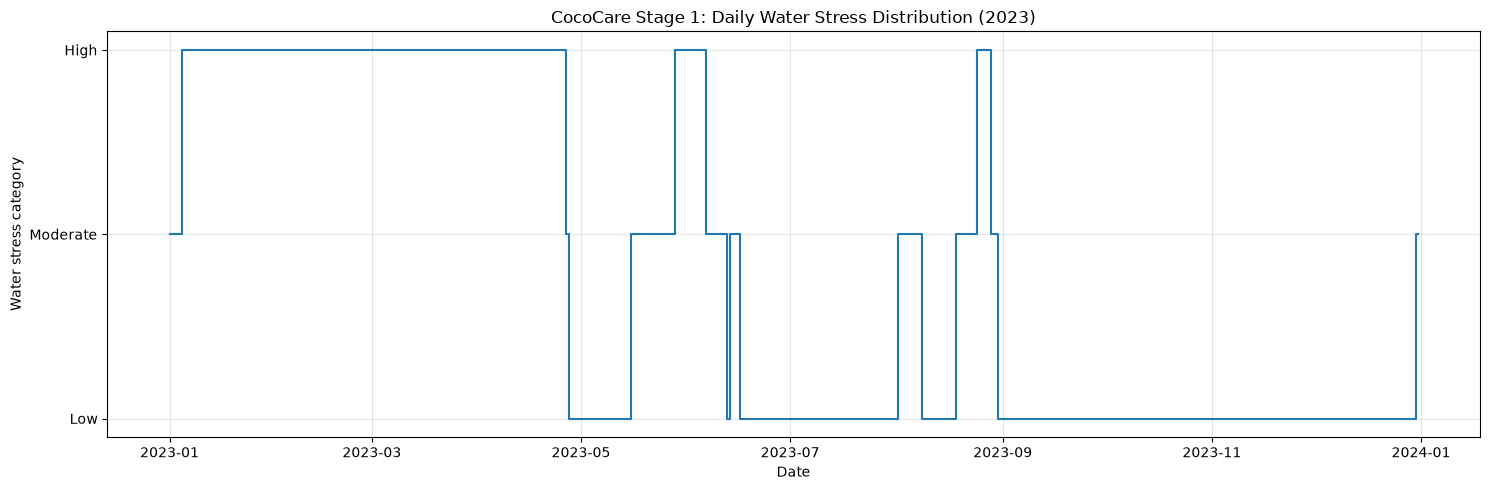

In [14]:

import matplotlib.pyplot as plt
import pandas as pd

# Target labels over time
class_map = {
    "low": 0,
    "moderate": 1,
    "high": 2
}

plot_df = df.copy()
plot_df["stress_numeric"] = (
    plot_df["water_stress_rule_derived"].map(class_map)
)

fig, ax = plt.subplots(figsize=(15, 5))

ax.step(
    plot_df["date"],
    plot_df["stress_numeric"],
    where="mid",
    linewidth=1.5
)

ax.set_yticks([0, 1, 2])
ax.set_yticklabels(["Low", "Moderate", "High"])

ax.set_title(
    "CocoCare Stage 1: Daily Water Stress Distribution (2023)"
)
ax.set_xlabel("Date")
ax.set_ylabel("Water stress category")

ax.grid(True, alpha=0.3)
fig.tight_layout()

fig.savefig(
    "stage1_target_timeline.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Stress transition matrix:
Current day   high  low  moderate
Previous day                     
high           122    0         3
low              0  192         5
moderate         3    5        34

Monthly stress distribution:
water_stress_rule_derived    high     low  moderate
date                                               
1                           87.10    0.00     12.90
2                          100.00    0.00      0.00
3                          100.00    0.00      0.00
4                           86.67   10.00      3.33
5                            9.68   48.39     41.94
6                           20.00   50.00     30.00
7                            0.00  100.00      0.00
8                           12.90   38.71     48.39
9                            0.00  100.00      0.00
10                           0.00  100.00      0.00
11                           0.00  100.00      0.00
12                           0.00   96.77      3.23


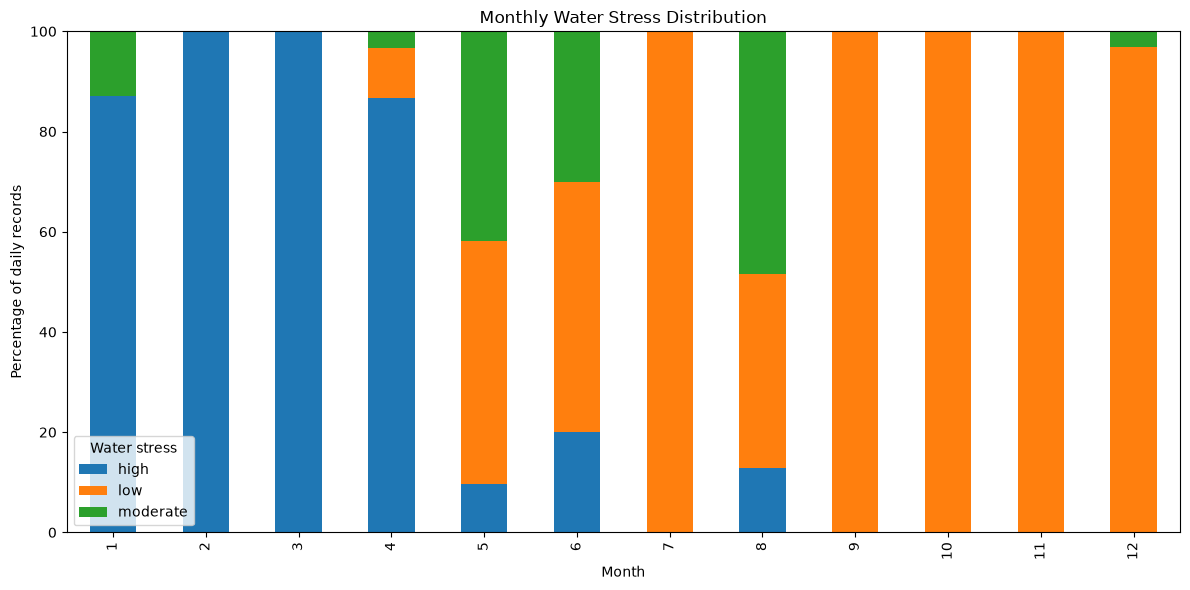

In [15]:

# Count transitions between consecutive stress labels

transition_data = pd.crosstab(
    df["water_stress_rule_derived"].shift(1),
    df["water_stress_rule_derived"],
    rownames=["Previous day"],
    colnames=["Current day"]
)

print("Stress transition matrix:")
print(transition_data)

print("\nMonthly stress distribution:")

monthly_distribution = pd.crosstab(
    df["date"].dt.month,
    df["water_stress_rule_derived"],
    normalize="index"
) * 100

print(monthly_distribution.round(2))

# Save the monthly distribution
monthly_distribution.to_csv(
    "stage1_monthly_stress_distribution.csv"
)

# Plot monthly distribution
ax = monthly_distribution.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

ax.set_title("Monthly Water Stress Distribution")
ax.set_xlabel("Month")
ax.set_ylabel("Percentage of daily records")
ax.legend(title="Water stress")

plt.tight_layout()
plt.savefig(
    "stage1_monthly_stress_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [18]:

# ==========================================
# REBUILD NEXT-DAY DATASET
# ==========================================

# Ensure target date exists
df["target_date_next"] = df["date"].shift(-1)

# Create target-date seasonal features
next_day_number = df["target_date_next"].dt.dayofyear

df["next_day_sin"] = np.sin(
    2 * np.pi * next_day_number / 365.25
)

df["next_day_cos"] = np.cos(
    2 * np.pi * next_day_number / 365.25
)

# Next-day feature set
next_features = (
    engineered_features
    + ["next_day_sin", "next_day_cos"]
)

# Rebuild next-day dataset AFTER adding features
next_data = df.dropna(
    subset=next_features + [
        "target_next_day",
        "target_date_next"
    ]
).copy()

# Recreate chronological splits
next_train, next_val, next_test = chronological_split(
    next_data,
    "target_date_next"
)

# Verify
print("Next-day feature verification:")
print("Feature count:", len(next_features))

print(
    next_data[
        [
            "date",
            "target_date_next",
            "next_day_sin",
            "next_day_cos"
        ]
    ].head()
)

print("\nNext-day split sizes:")
print(len(next_train), len(next_val), len(next_test))

assert "next_day_sin" in next_data.columns
assert "next_day_cos" in next_data.columns

print("\nNext-day dataset rebuilt successfully.")


Next-day feature verification:
Feature count: 34
         date target_date_next  next_day_sin  next_day_cos
13 2023-01-14       2023-01-15      0.255182      0.966893
14 2023-01-15       2023-01-16      0.271777      0.962360
15 2023-01-16       2023-01-17      0.288291      0.957543
16 2023-01-17       2023-01-18      0.304719      0.952442
17 2023-01-18       2023-01-19      0.321058      0.947060

Next-day split sizes:
245 53 53

Next-day dataset rebuilt successfully.


            rainfall_mm  et0_mm_day  soil_water_storage_mm_modelled  \
date                                                                  
2023-01-31        10.10       3.508                          16.413   
2023-02-28         9.54       4.766                           5.495   
2023-03-31        46.82       5.112                           8.309   
2023-04-30       104.88       5.156                          16.049   
2023-05-31        99.80       4.338                          43.319   
2023-06-30       152.43       4.162                          43.032   
2023-07-31       215.45       3.445                          56.113   
2023-08-31        94.14       4.335                          38.776   
2023-09-30       256.25       3.593                          58.217   
2023-10-31       246.77       3.402                          56.495   
2023-11-30       235.99       2.801                          57.927   
2023-12-31       110.00       2.593                          54.359   

     

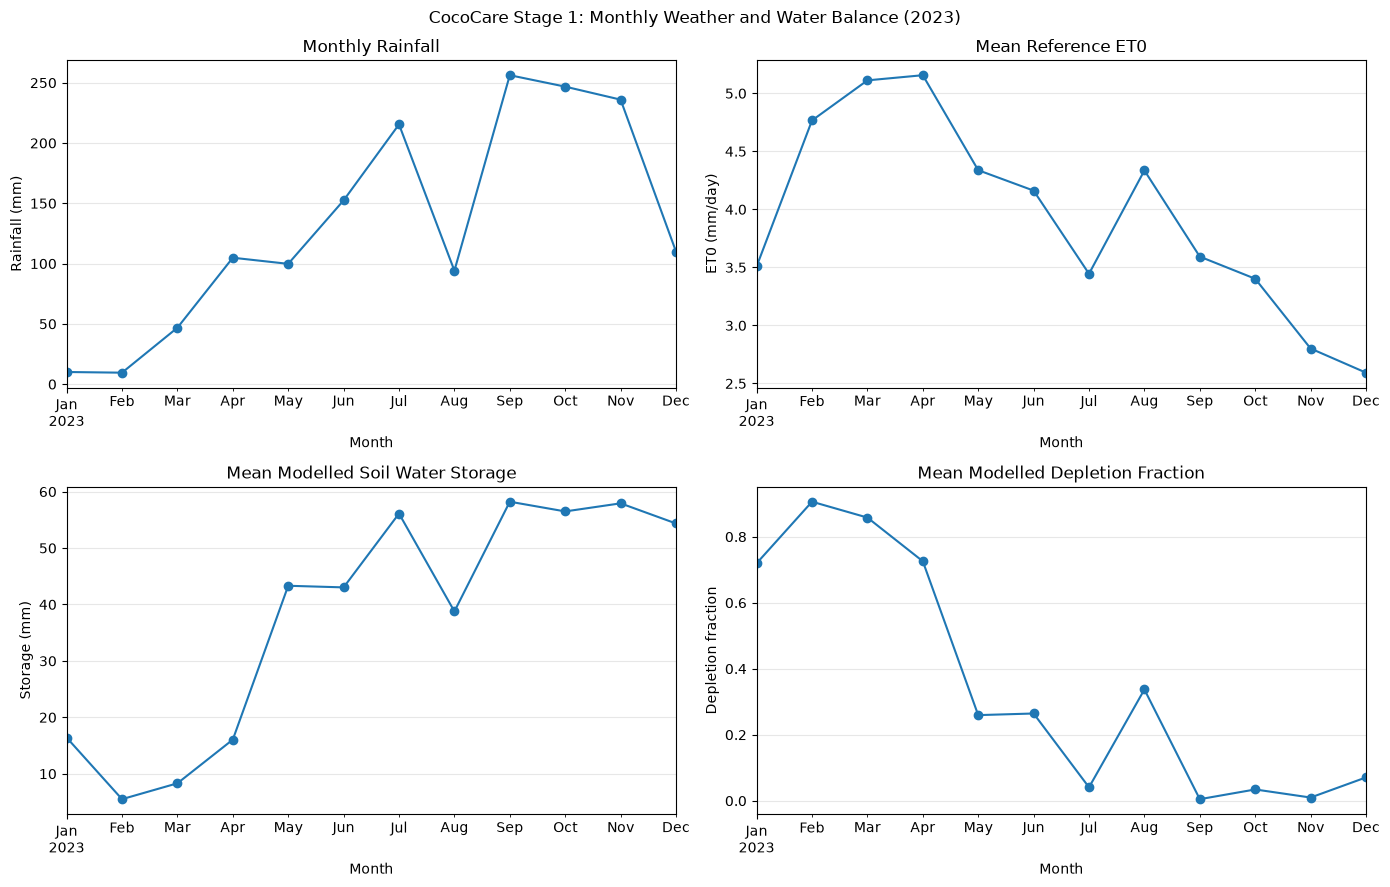

In [19]:

# ==========================================
# MONTHLY WEATHER AND WATER BALANCE ANALYSIS
# ==========================================

monthly = df.set_index("date").resample("ME").agg({
    "rainfall_mm": "sum",
    "et0_mm_day": "mean",
    "soil_water_storage_mm_modelled": "mean",
    "depletion_fraction_modelled": "mean"
})

print(monthly.round(3))

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 9)
)

monthly["rainfall_mm"].plot(
    ax=axes[0, 0],
    marker="o"
)
axes[0, 0].set_title("Monthly Rainfall")
axes[0, 0].set_ylabel("Rainfall (mm)")

monthly["et0_mm_day"].plot(
    ax=axes[0, 1],
    marker="o"
)
axes[0, 1].set_title("Mean Reference ET0")
axes[0, 1].set_ylabel("ET0 (mm/day)")

monthly["soil_water_storage_mm_modelled"].plot(
    ax=axes[1, 0],
    marker="o"
)
axes[1, 0].set_title("Mean Modelled Soil Water Storage")
axes[1, 0].set_ylabel("Storage (mm)")

monthly["depletion_fraction_modelled"].plot(
    ax=axes[1, 1],
    marker="o"
)
axes[1, 1].set_title("Mean Modelled Depletion Fraction")
axes[1, 1].set_ylabel("Depletion fraction")

for ax in axes.flat:
    ax.set_xlabel("Month")
    ax.grid(alpha=0.3)

fig.suptitle(
    "CocoCare Stage 1: Monthly Weather and Water Balance (2023)"
)

plt.tight_layout()
plt.savefig(
    "stage1_monthly_water_balance_analysis.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [20]:

# ==========================================
# STRESS LABEL TRANSITION ANALYSIS
# ==========================================

transition_matrix = pd.crosstab(
    df["water_stress_rule_derived"].shift(1),
    df["water_stress_rule_derived"],
    rownames=["Previous day"],
    colnames=["Current day"],
    dropna=True
)

print("STRESS TRANSITION MATRIX")
print(transition_matrix)

print("\nROW NORMALIZED TRANSITION MATRIX")
print(
    transition_matrix.div(
        transition_matrix.sum(axis=1),
        axis=0
    ).round(3)
)

print("\nMONTHLY CLASS COUNTS")
print(
    pd.crosstab(
        df["date"].dt.month,
        df["water_stress_rule_derived"]
    )
)


STRESS TRANSITION MATRIX
Current day   high  low  moderate
Previous day                     
high           122    0         3
low              0  192         5
moderate         3    5        34

ROW NORMALIZED TRANSITION MATRIX
Current day    high    low  moderate
Previous day                        
high          0.976  0.000     0.024
low           0.000  0.975     0.025
moderate      0.071  0.119     0.810

MONTHLY CLASS COUNTS
water_stress_rule_derived  high  low  moderate
date                                          
1                            27    0         4
2                            28    0         0
3                            31    0         0
4                            26    3         1
5                             3   15        13
6                             6   15         9
7                             0   31         0
8                             4   12        15
9                             0   30         0
10                            0   31         0
